# Descriptores de forma, paso a paso

Visión Artificial · CUTLAJO

¿Cómo sabe una computadora que algo es un círculo y no un cuadrado? No "ve" formas: ve números. En este notebook vamos de una imagen a color a un conjunto de **descriptores numéricos** que describen la forma de cada figura.

```
original → gris → binaria → limpieza morfológica → etiquetas → regionprops → descriptores → clasificación
```

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import measure

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"


def mostrar(*imagenes, titulos=None, tam=4):
    """Muestra varias imágenes lado a lado. Las de 3 canales se asumen BGR (OpenCV)."""
    fig, ejes = plt.subplots(1, len(imagenes), figsize=(tam * len(imagenes), tam))
    ejes = np.atleast_1d(ejes)
    for i, (ax, im) in enumerate(zip(ejes, imagenes)):
        if im.ndim == 3:
            im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        ax.imshow(im, vmin=0, vmax=255 if im.dtype == np.uint8 else None)
        ax.set_title(titulos[i] if titulos else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. La imagen original

OpenCV lee las imágenes como una matriz de `alto × ancho × 3` en orden **BGR** (no RGB).

Tamaño: (480, 640, 3)   tipo: uint8
Pixel del fondo (BGR): [230 230 230]
Pixel del círculo (BGR): [ 32  30 220]


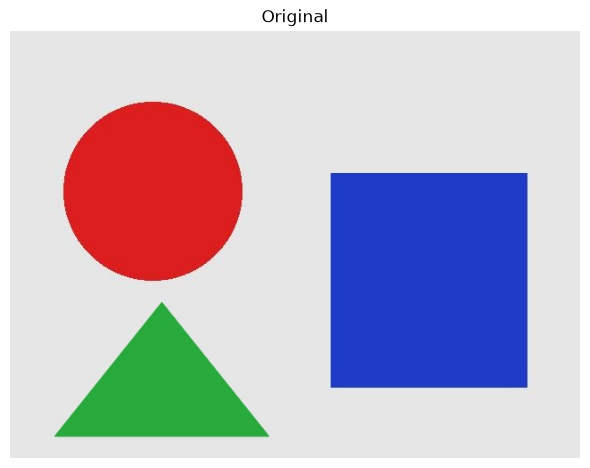

In [2]:
imagen = cv2.imread("formas.jpg")
print("Tamaño:", imagen.shape, "  tipo:", imagen.dtype)
print("Pixel del fondo (BGR):", imagen[10, 10])
print("Pixel del círculo (BGR):", imagen[180, 160])
mostrar(imagen, titulos=["Original"], tam=6)

## 2. Escala de grises

Para separar figura de fondo no necesitamos el color, solo **qué tan claro** es cada píxel. OpenCV usa:

$$ gris = 0.299\,R + 0.587\,G + 0.114\,B $$

El histograma nos dice cuántos píxeles hay de cada nivel de gris. Fíjate: un pico enorme a la derecha (el fondo claro) y picos chicos a la izquierda (las figuras).

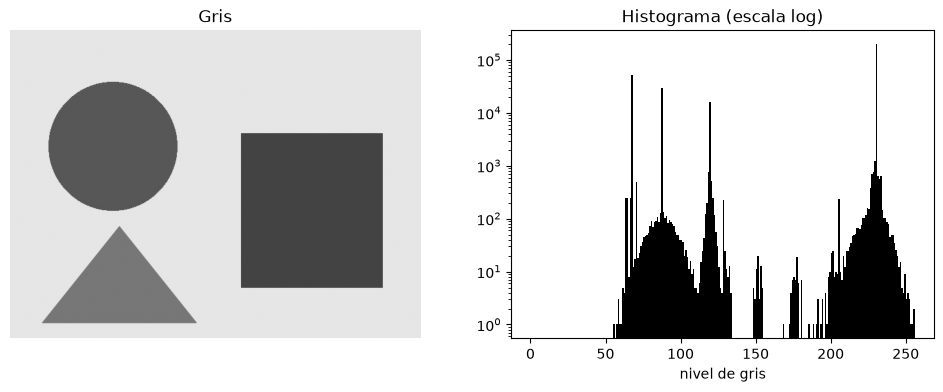

In [3]:
gris = cv2.cvtColor(imagen, cv2.COLOR_BGR2GRAY)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.imshow(gris, vmin=0, vmax=255); a1.set_title("Gris"); a1.axis("off")
a2.hist(gris.ravel(), bins=256, range=(0, 256), color="k")
a2.set_yscale("log"); a2.set_title("Histograma (escala log)"); a2.set_xlabel("nivel de gris")
plt.show()

## 3. Binarización: blanco y negro

Elegimos un **umbral** *T*: lo que esté por debajo es figura y lo que esté por arriba es fondo. Como las figuras son **más oscuras** que el fondo, usamos `THRESH_BINARY_INV` para que las figuras queden en **blanco (255)** y el fondo en **negro (0)**. Por convención, en visión las regiones de interés van en blanco.

Prueba varios umbrales a mano. ¿Qué pasa con T = 100? ¿Y con T = 235?

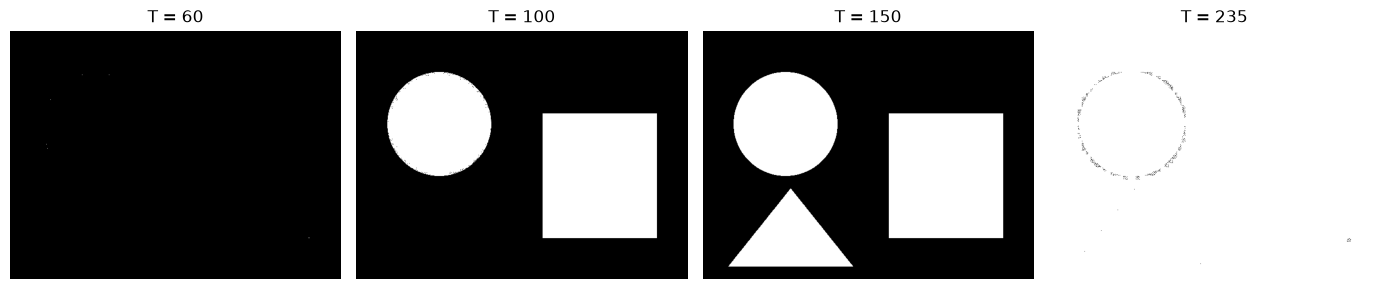

In [4]:
umbrales = [60, 100, 150, 235]
binarias = [cv2.threshold(gris, t, 255, cv2.THRESH_BINARY_INV)[1] for t in umbrales]
mostrar(*binarias, titulos=[f"T = {t}" for t in umbrales], tam=3.5)

Con T muy bajo perdemos figuras (el triángulo verde es más claro que las otras). Con T muy alto se nos mete el fondo.

**Otsu** elige el umbral automáticamente: busca el valor que mejor separa los dos grupos del histograma (minimiza la varianza dentro de cada grupo).

Umbral de Otsu: 154
Valores únicos en la imagen binaria: [  0 255]


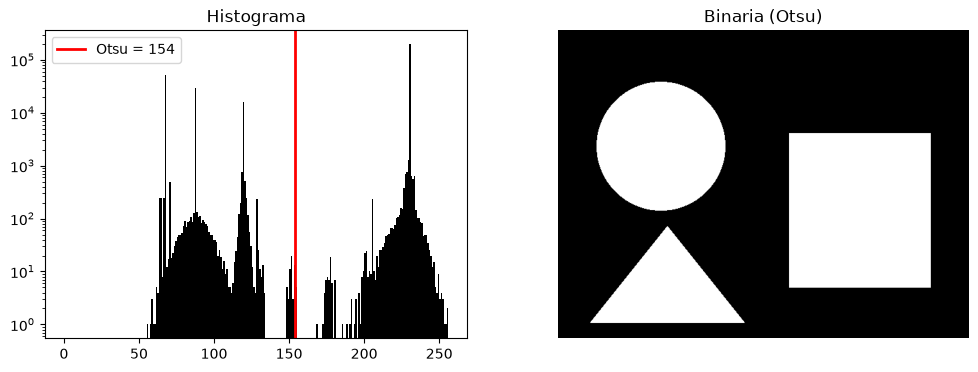

In [5]:
T, binaria = cv2.threshold(gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
print(f"Umbral de Otsu: {T:.0f}")
print("Valores únicos en la imagen binaria:", np.unique(binaria))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.hist(gris.ravel(), bins=256, range=(0, 256), color="k"); a1.set_yscale("log")
a1.axvline(T, color="r", lw=2, label=f"Otsu = {T:.0f}"); a1.legend(); a1.set_title("Histograma")
a2.imshow(binaria); a2.set_title("Binaria (Otsu)"); a2.axis("off")
plt.show()

## 4. Morfología: limpiar la imagen binaria

Las operaciones morfológicas pasan un **elemento estructurante** (un *kernel*, una plantilla pequeña) por toda la imagen:

| Operación | Qué hace | Para qué sirve |
|---|---|---|
| **Erosión** | un píxel queda blanco solo si *todo* el kernel cae sobre blanco | adelgaza, borra puntitos |
| **Dilatación** | un píxel queda blanco si *algo* del kernel toca blanco | engorda, tapa huecos |
| **Apertura** | erosión → dilatación | quita ruido sin cambiar el tamaño |
| **Cierre** | dilatación → erosión | rellena huecos sin cambiar el tamaño |

Nuestra imagen está muy limpia, así que primero **le metemos ruido** a propósito para ver el efecto.

Kernel 5x5 elíptico:
 [[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


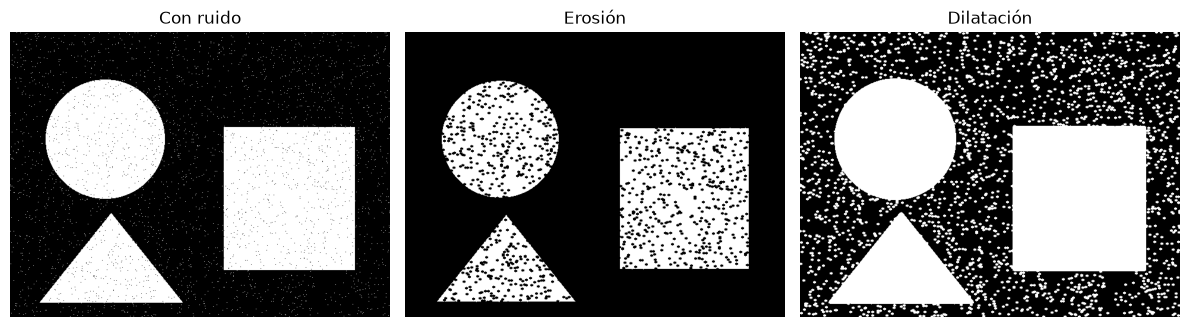

In [6]:
rng = np.random.default_rng(0)
sucia = binaria.copy()
sucia[rng.random(sucia.shape) < 0.01] = 255   # 1% de puntos blancos en el fondo (sal)
sucia[rng.random(sucia.shape) < 0.01] = 0     # 1% de huecos negros en las figuras (pimienta)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
print("Kernel 5x5 elíptico:\n", kernel)

erosion = cv2.erode(sucia, kernel)
dilatacion = cv2.dilate(sucia, kernel)
mostrar(sucia, erosion, dilatacion, titulos=["Con ruido", "Erosión", "Dilatación"])

La erosión borra los puntos del fondo, pero **agranda** los huecos de las figuras. La dilatación hace lo contrario. Por eso se combinan:

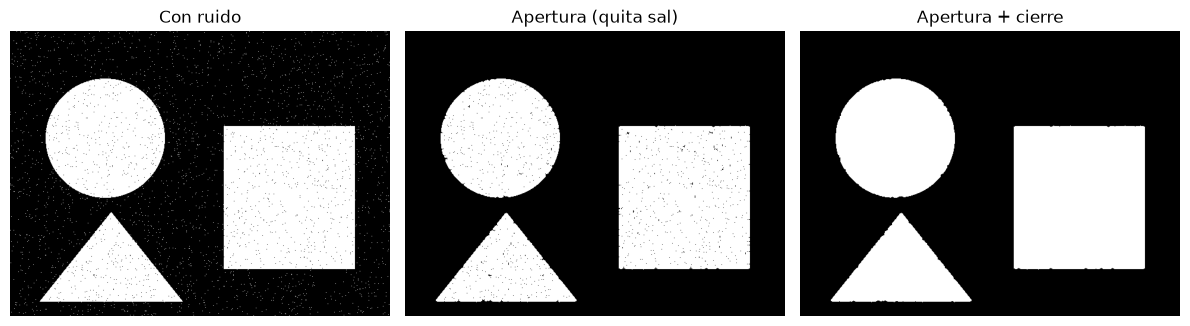

In [7]:
apertura = cv2.morphologyEx(sucia, cv2.MORPH_OPEN, kernel)
limpia = cv2.morphologyEx(apertura, cv2.MORPH_CLOSE, kernel)
mostrar(sucia, apertura, limpia, titulos=["Con ruido", "Apertura (quita sal)", "Apertura + cierre"])

Funcionó. De aquí en adelante seguimos con la binaria original (sin ruido) para que los números salgan exactos.

## 5. Etiquetado de componentes conectadas

La imagen binaria solo dice "figura / no figura". Para medir cada figura por separado, `measure.label` le asigna un **número distinto a cada grupo de píxeles blancos conectados**: 0 al fondo, 1 a la primera figura, 2 a la segunda...

Etiquetas encontradas: [0 1 2 3]


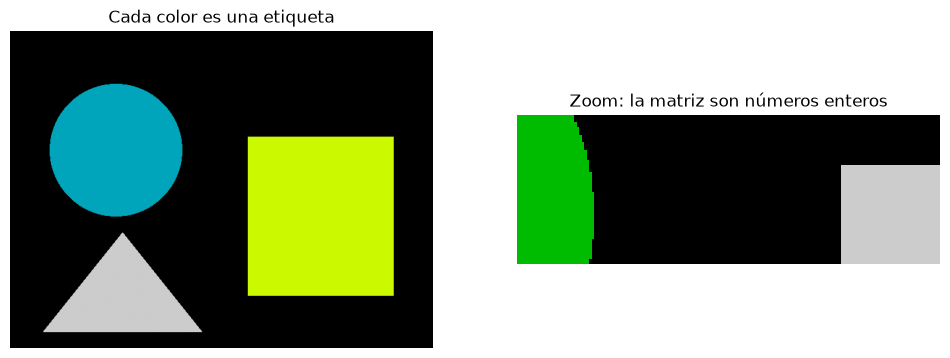

In [8]:
etiquetas = measure.label(binaria > 0, connectivity=2)
print("Etiquetas encontradas:", np.unique(etiquetas))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.imshow(etiquetas, cmap="nipy_spectral"); a1.set_title("Cada color es una etiqueta"); a1.axis("off")
a2.imshow(etiquetas[140:200, 230:400], cmap="nipy_spectral", interpolation="nearest")
a2.set_title("Zoom: la matriz son números enteros"); a2.axis("off")
plt.show()

## 6. `regionprops`: medir cada región

`measure.regionprops` recibe la imagen de etiquetas y regresa un objeto por región con decenas de propiedades ya calculadas.

In [9]:
regiones = measure.regionprops(etiquetas)
for r in regiones:
    print(f"Región {r.label}: área={r.area:.0f}  centroide=({r.centroid[1]:.0f}, {r.centroid[0]:.0f})  "
          f"bbox={r.bbox}")

Región 1: área=31689  centroide=(160, 180)  bbox=(80, 60, 281, 261)
Región 2: área=53261  centroide=(470, 280)  bbox=(160, 360, 401, 581)
Región 3: área=18331  centroide=(170, 405)  bbox=(305, 50, 456, 291)


## 7. Los descriptores, uno por uno

### 7.1 Área y perímetro
- **Área**: número de píxeles de la región.
- **Perímetro**: longitud del borde.

Dependen del **tamaño**: un círculo grande y uno chico tienen áreas distintas aunque tengan la misma forma. Por eso los descriptores que siguen son **cocientes** que no dependen de la escala.

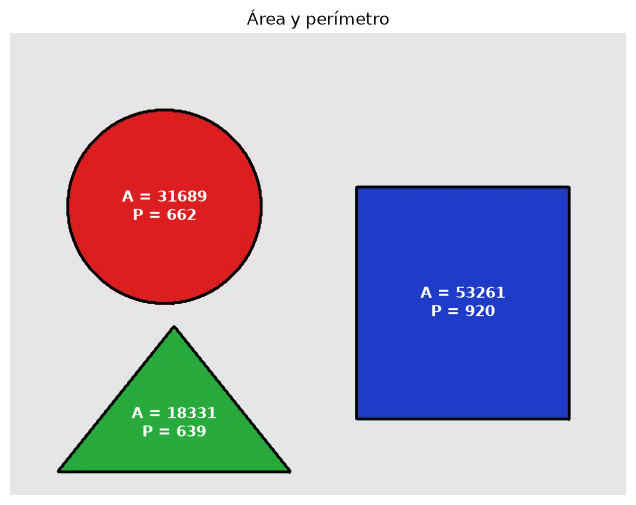

In [10]:
fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
for r in regiones:
    for contorno in measure.find_contours(etiquetas == r.label, 0.5):
        ax.plot(contorno[:, 1], contorno[:, 0], "k", lw=2)
    ax.text(r.centroid[1], r.centroid[0], f"A = {r.area:.0f}\nP = {r.perimeter:.0f}",
            ha="center", va="center", color="w", fontsize=11, weight="bold")
ax.set_title("Área y perímetro"); ax.axis("off")
plt.show()

### 7.2 Circularidad

$$ circularidad = \frac{4\pi \cdot área}{perímetro^2} $$

De todas las figuras con el mismo perímetro, el círculo es la que encierra más área. Por eso esta razón vale **1 en un círculo perfecto** y baja mientras más esquinas o picos tenga la figura.

| Figura | Valor teórico |
|---|---|
| Círculo | 1 |
| Cuadrado | π/4 ≈ 0.785 |
| Triángulo equilátero | ≈ 0.605 |

Nuestro triángulo es más ancho que alto (no es equilátero), así que sale un poco más bajo.

In [11]:
for r in regiones:
    circ = 4 * np.pi * r.area / r.perimeter**2
    print(f"Región {r.label}: circularidad = {circ:.3f}")

Región 1: circularidad = 0.909
Región 2: circularidad = 0.791
Región 3: circularidad = 0.564


> **¿Por qué el círculo no da exactamente 1?** En píxeles, el borde del círculo es una escalerita, y la escalerita es más larga que la curva real. El perímetro sale sobreestimado y la circularidad baja un poco. Esto se llama **error de discretización**.

### 7.3 Extensión (*extent*)

$$ extensión = \frac{área}{área\ de\ la\ caja\ envolvente} $$

¿Qué fracción de su caja (*bounding box*) llena la figura? Un cuadrado la llena toda (1), un círculo π/4 ≈ 0.785 y un triángulo la mitad (0.5).

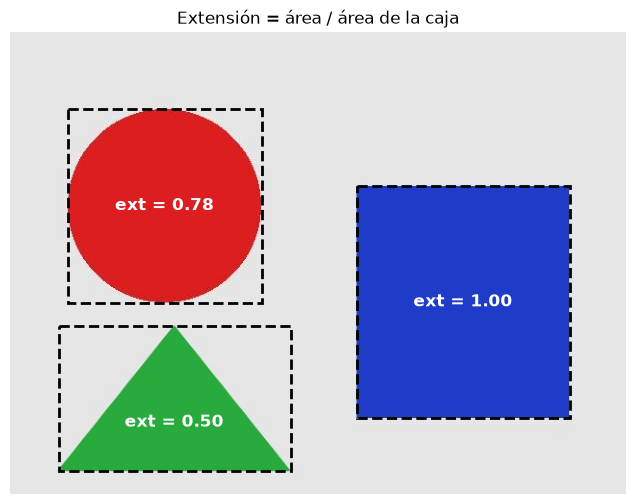

In [12]:
fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
for r in regiones:
    y0, x0, y1, x1 = r.bbox
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="k", lw=2, ls="--"))
    ax.text(r.centroid[1], r.centroid[0], f"ext = {r.extent:.2f}",
            ha="center", va="center", color="w", fontsize=12, weight="bold")
ax.set_title("Extensión = área / área de la caja"); ax.axis("off")
plt.show()

### 7.4 Casco convexo, solidez y convexidad

El **casco convexo** (*convex hull*) es la figura que formaría una liga estirada alrededor de la región.

$$ solidez = \frac{área}{área\ del\ casco} \qquad convexidad = \frac{perímetro\ del\ casco}{perímetro} $$

Las dos valen **1 si la figura no tiene entrantes**. Nuestras tres figuras son convexas, así que aquí no se ve nada interesante... para eso dibujamos una **estrella** y una **L**.

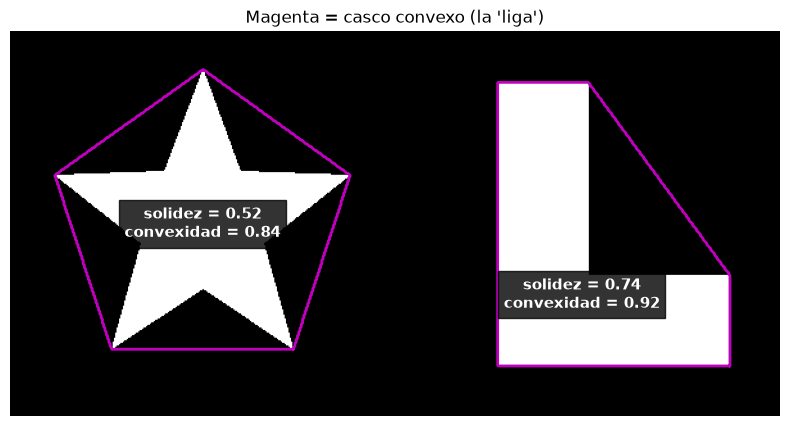

In [13]:
def perimetro_casco(r):
    return measure.perimeter(np.pad(r.image_convex, 1))


# Figuras no convexas dibujadas en una imagen aparte
extra = np.zeros((300, 600), np.uint8)
angulos = np.linspace(-np.pi / 2, 3 * np.pi / 2, 11)[:-1]
radios = np.where(np.arange(10) % 2 == 0, 120, 50)
estrella = np.stack([150 + radios * np.cos(angulos), 150 + radios * np.sin(angulos)], 1).astype(np.int32)
cv2.fillPoly(extra, [estrella], 255)
cv2.fillPoly(extra, [np.array([[380, 40], [450, 40], [450, 190], [560, 190], [560, 260], [380, 260]])], 255)

etiq_extra = measure.label(extra > 0)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(extra)
for r in measure.regionprops(etiq_extra):
    casco = r.image_convex
    y0, x0, _, _ = r.bbox
    for c in measure.find_contours(np.pad(casco, 1), 0.5):
        ax.plot(c[:, 1] + x0 - 1, c[:, 0] + y0 - 1, "m", lw=2)
    ax.text(r.centroid[1], r.centroid[0] + (0 if r.label == 1 else 30),
            f"solidez = {r.solidity:.2f}\nconvexidad = {perimetro_casco(r) / r.perimeter:.2f}",
            ha="center", va="center", color="w", fontsize=11, weight="bold",
            bbox=dict(facecolor="k", alpha=0.8))
ax.set_title("Magenta = casco convexo (la 'liga')"); ax.axis("off")
plt.show()

La parte entre la figura y la liga es lo que "falta" para ser convexa. Mientras más grande, menor la solidez.

### 7.5 Excentricidad y relación de aspecto

`regionprops` ajusta una **elipse** con los mismos momentos de segundo orden que la región.

- **Excentricidad**: 0 si la elipse es un círculo; se acerca a 1 mientras más alargada.
- **Relación de aspecto**: ancho / alto de la caja.

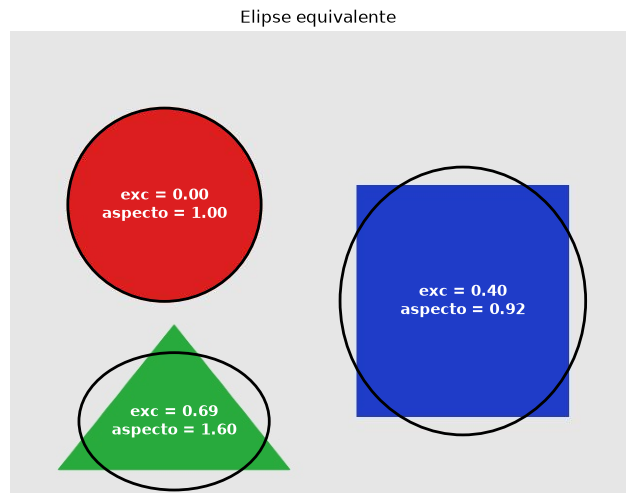

In [14]:
from matplotlib.patches import Ellipse

fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
for r in regiones:
    cy, cx = r.centroid
    ax.add_patch(Ellipse((cx, cy), r.axis_minor_length, r.axis_major_length,
                         angle=-np.degrees(r.orientation), fill=False, ec="k", lw=2))
    y0, x0, y1, x1 = r.bbox
    ax.text(cx, cy, f"exc = {r.eccentricity:.2f}\naspecto = {(x1 - x0) / (y1 - y0):.2f}",
            ha="center", va="center", color="w", fontsize=11, weight="bold")
ax.set_title("Elipse equivalente"); ax.axis("off")
plt.show()

## 8. Tabla resumen

Juntamos todos los descriptores. Compara cada columna con los valores teóricos de arriba.

In [15]:
def descriptores(r):
    y0, x0, y1, x1 = r.bbox
    return {
        "área": r.area,
        "perímetro": r.perimeter,
        "circularidad": 4 * np.pi * r.area / r.perimeter**2,
        "extensión": r.extent,
        "solidez": r.solidity,
        "convexidad": perimetro_casco(r) / r.perimeter,
        "excentricidad": r.eccentricity,
        "aspecto": (x1 - x0) / (y1 - y0),
    }


tabla = {r.label: descriptores(r) for r in regiones}
nombres = list(next(iter(tabla.values())))
print(f"{'región':>8}" + "".join(f"{n:>14}" for n in nombres))
for etiqueta, d in tabla.items():
    print(f"{etiqueta:>8}" + "".join(f"{v:>14.3f}" for v in d.values()))

  región          área     perímetro  circularidad     extensión       solidez    convexidad excentricidad       aspecto
       1     31689.000       661.754         0.909         0.784         0.994         1.000         0.000         1.000
       2     53261.000       920.000         0.791         1.000         1.000         1.000         0.399         0.917
       3     18331.000       638.997         0.564         0.504         0.994         1.001         0.692         1.596


## 9. Clasificar con reglas

Con estos números podemos escribir reglas simples. Fíjate que **ninguna regla mira el color ni el tamaño**, solo la forma.

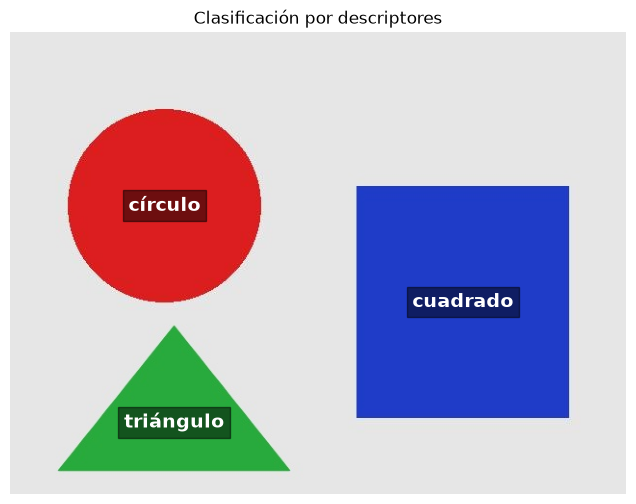

In [16]:
def clasificar(d):
    if d["circularidad"] > 0.85 and d["excentricidad"] < 0.3:
        return "círculo"
    if d["extensión"] > 0.9:
        return "cuadrado" if 0.9 < d["aspecto"] < 1.1 else "rectángulo"
    if 0.4 < d["extensión"] < 0.6 and d["solidez"] > 0.95:
        return "triángulo"
    return "?"


fig, ax = plt.subplots()
ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))
for r in regiones:
    forma = clasificar(tabla[r.label])
    ax.text(r.centroid[1], r.centroid[0], forma, ha="center", va="center",
            color="w", fontsize=14, weight="bold", bbox=dict(facecolor="k", alpha=0.5))
ax.set_title("Clasificación por descriptores"); ax.axis("off")
plt.show()